# Multi-class Classification
**IBM Machine Learning with Python Lab**

Estimated time needed: **30 mins**

In this lab, you will learn the different strategies of Multi-class classification and implement the same on a real-world dataset.

---

### Objectives
After completing this lab you will be able to:
- Understand the use of one-hot encoding for categorical variables.
- Implement logistic regression for multi-class classification using One-vs-All (OvA) and One-vs-One (OvO) strategies.
- Evaluate model performance using appropriate metrics.

## 1. Import Necessary Libraries

First, to ensure the availability of the required libraries, execute the cell below.

In [1]:
# Make sure the required libraries are available
# !pip install numpy==2.2.0
# !pip install pandas==2.2.3
# !pip install scikit-learn==1.6.0
# !pip install matplotlib==3.9.3
# !pip install seaborn==0.13.2

Now, import the necessary libraries for data processing, model training, and evaluation.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression as _OriginalLR
from sklearn.multiclass import OneVsRestClassifier, OneVsOneClassifier
from sklearn.metrics import accuracy_score

import warnings
warnings.filterwarnings('ignore')

# Compatibility wrapper for LogisticRegression multi_class parameter across scikit-learn versions
class LogisticRegression:
    def __new__(cls, *args, **kwargs):
        multi_class = kwargs.pop('multi_class', None)
        if multi_class == 'ovr':
            base = _OriginalLR(*args, **kwargs)
            ovr = OneVsRestClassifier(base)
            type(ovr).coef_ = property(lambda self: np.vstack([est.coef_ for est in self.estimators_]))
            type(ovr).intercept_ = property(lambda self: np.array([est.intercept_[0] for est in self.estimators_]))
            return ovr
        return _OriginalLR(*args, **kwargs)

## 2. About the Dataset

The data set being used for this lab is the "Obesity Risk Prediction" data set publically available on [UCI Library](https://archive.ics.uci.edu/dataset/544/estimation+of+obesity+levels+based+on+eating+habits+and+physical+condition) under the [CCA 4.0](https://creativecommons.org/licenses/by/4.0/legalcode) license. The data set has 17 attributes in total along with 2,111 samples.

The attributes of the dataset are described below:

| Variable Name | Type | Description |
| :--- | :--- | :--- |
| **Gender** | Categorical | Gender of the individual |
| **Age** | Continuous | Age in years |
| **Height** | Continuous | Height in meters |
| **Weight** | Continuous | Weight in kilograms |
| **family_history_with_overweight** | Binary | Has a family member suffered or suffers from overweight? |
| **FAVC** | Binary | Do you eat high caloric food frequently? |
| **FCVC** | Integer | Do you usually eat vegetables in your meals? |
| **NCP** | Continuous | How many main meals do you have daily? |
| **CAEC** | Categorical | Do you eat any food between meals? |
| **SMOKE** | Binary | Do you smoke? |
| **CH2O** | Continuous | How much water do you drink daily? |
| **SCC** | Binary | Do you monitor the calories you eat daily? |
| **FAF** | Continuous | How often do you have physical activity? |
| **TUE** | Integer | How much time do you use technological devices such as cell phone, videogames, television, computer and others? |
| **CALC** | Categorical | How often do you drink alcohol? |
| **MTRANS** | Categorical | Which transportation do you usually use? |
| **NObeyesdad** | Categorical | Obesity level (Target variable) |

## 3. Load the Dataset

Load the data set by executing the code cell below.

In [3]:
file_path = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/GkDzb7bWrtvGXdPOfk6CIg/Obesity-level-prediction-dataset.csv"
data = pd.read_csv(file_path)
data.head()

,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


## 4. Exploratory Data Analysis

Visualize the distribution of the target variable to understand the class balance.

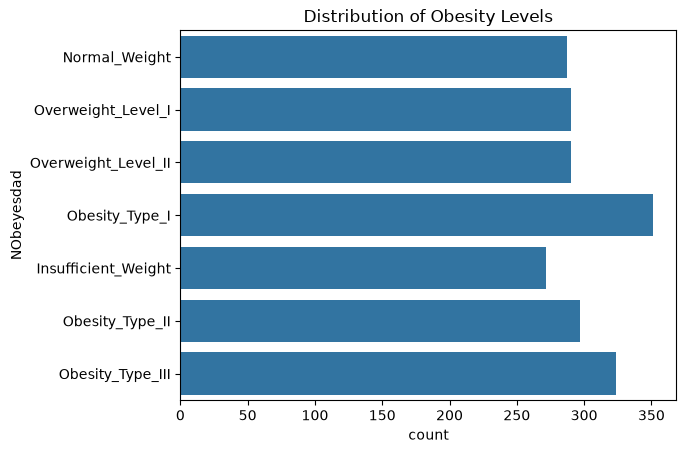

In [4]:
# Distribution of target variable
sns.countplot(y='NObeyesdad', data=data)
plt.title('Distribution of Obesity Levels')
plt.show()

This shows that the dataset is fairly balanced and does not require any special attention in terms of biased training.

---

### Exercise 1
Check for null values, and display a summary of the dataset (use `.info()` and `.describe()` methods).

<details><summary>Click here for the solution</summary>

```python
# Checking for null values
print(data.isnull().sum())

# Dataset summary
print(data.info())
print(data.describe())
```

**Expected Output:**
- Counts of null values for each column (likely zero for this dataset).
- Dataset info including column names, data types, and memory usage.
- Descriptive statistics for numerical columns.

</details>

In [5]:
# Checking for null values
print("--- Checking for null values ---")
print(data.isnull().sum())

# Dataset summary
print("\n--- Dataset Info ---")
data.info()

print("\n--- Descriptive Statistics ---")
data.describe()

--- Checking for null values ---
Gender                            0
Age                               0
Height                            0
Weight                            0
family_history_with_overweight    0
FAVC                              0
FCVC                              0
NCP                               0
CAEC                              0
SMOKE                             0
CH2O                              0
SCC                               0
FAF                               0
TUE                               0
CALC                              0
MTRANS                            0
NObeyesdad                        0
dtype: int64

--- Dataset Info ---
<class 'pandas.DataFrame'>
RangeIndex: 2111 entries, 0 to 2110
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Gender                          2111 non-null   str    
 1   Age                             2111

,Age,Height,Weight,FCVC,NCP,CH2O,FAF,TUE
count,2111.000000,2111.000000,2111.000000,2111.000000,2111.000000,2111.000000,2111.000000,2111.000000
mean,24.312600,1.701677,86.586058,2.419043,2.685628,2.008011,1.010298,0.657866
std,6.345968,0.093305,26.191172,0.533927,0.778039,0.612953,0.850592,0.608927
min,14.000000,1.450000,39.000000,1.000000,1.000000,1.000000,0.000000,0.000000
25%,19.947192,1.630000,65.473343,2.000000,2.658738,1.584812,0.124505,0.000000
50%,22.777890,1.700499,83.000000,2.385502,3.000000,2.000000,1.000000,0.625350
75%,26.000000,1.768464,107.430682,3.000000,3.000000,2.477420,1.666678,1.000000
max,61.000000,1.980000,173.000000,3.000000,4.000000,3.000000,3.000000,2.000000


## 5. Preprocessing the Data

### Feature scaling
Scale the numerical features to standardize their ranges for better model performance.

In [6]:
# Standardizing continuous numerical features
continuous_columns = data.select_dtypes(include=['float64']).columns.tolist()

scaler = StandardScaler()
scaled_features = scaler.fit_transform(data[continuous_columns])

# Converting to a DataFrame
scaled_df = pd.DataFrame(scaled_features, columns=scaler.get_feature_names_out(continuous_columns))

# Combining with the original dataset
scaled_data = pd.concat([data.drop(columns=continuous_columns), scaled_df], axis=1)

Standardization of data is important to better define the decision boundaries between classes by making sure that the feature variations are in similar scales. The data is now ready to be used for training and testing.

### One-hot encoding
Convert categorical variables into numerical format using one-hot encoding.

In [7]:
# Identifying categorical columns
categorical_columns = scaled_data.select_dtypes(include=['object']).columns.tolist()
categorical_columns.remove('NObeyesdad') # Exclude target column

# Applying one-hot encoding
encoder = OneHotEncoder(sparse_output=False, drop='first')
encoded_features = encoder.fit_transform(scaled_data[categorical_columns])

# Converting to a DataFrame
encoded_df = pd.DataFrame(encoded_features, columns=encoder.get_feature_names_out(categorical_columns))

# Combining with the original dataset
prepped_data = pd.concat([scaled_data.drop(columns=categorical_columns), encoded_df], axis=1)

You will observe that all the categorical variables have now been modified to one-hot encoded features. This increases the overall number of fields to 24.

### Encode the target variable

In [8]:
# Encoding the target variable
prepped_data['NObeyesdad'] = prepped_data['NObeyesdad'].astype('category').cat.codes
prepped_data.head()

,NObeyesdad,Age,Height,Weight,FCVC,NCP,CH2O,FAF,TUE,Gender_Male,...,CAEC_no,SMOKE_yes,SCC_yes,CALC_Frequently,CALC_Sometimes,CALC_no,MTRANS_Bike,MTRANS_Motorbike,MTRANS_Public_Transportation,MTRANS_Walking
0,1,-0.522124,-0.875589,-0.862558,-0.785019,0.404153,-0.013073,-1.188039,0.561997,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
1,1,-0.522124,-1.947599,-1.168077,1.088342,0.404153,1.618759,2.339750,-1.080625,0.0,...,0.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
2,1,-0.206889,1.054029,-0.366090,-0.785019,0.404153,-0.013073,1.163820,0.561997,1.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
3,5,0.423582,1.054029,0.015808,1.088342,0.404153,-0.013073,1.163820,-1.080625,1.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
4,6,-0.364507,0.839627,0.122740,-0.785019,-2.167023,-0.013073,-1.188039,-1.080625,1.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0


### Separate the input and target data

In [9]:
# Preparing final dataset
X = prepped_data.drop('NObeyesdad', axis=1)
y = prepped_data['NObeyesdad']

## 6. Model Training and Evaluation

### Splitting the data set
Split the data into training and testing subsets.

In [10]:
# Splitting data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

## 7. Logistic Regression with One-vs-All (OvA)

In the One-vs-All approach:
- The algorithm trains a single binary classifier for each class.
- Each classifier learns to distinguish a single class from all the others combined.
- If there are $k$ classes, $k$ classifiers are trained.
- During prediction, the algorithm evaluates all classifiers on each input, and selects the class with the highest confidence score as the predicted class.

**Advantages:**
- Simpler and more efficient in terms of the number of classifiers ($k$).
- Easier to implement for algorithms that naturally provide confidence scores (e.g., logistic regression, SVM).

**Disadvantages:**
- Classifiers may struggle with class imbalance since each binary classifier must distinguish between one class and the rest.
- Requires the classifier to perform well even with highly imbalanced datasets, as the "all" group typically contains more samples than the "one" class.

Train a logistic regression model using the One-vs-All strategy and evaluate its performance.

In [11]:
# Training logistic regression model using One-vs-All (default)
model_ova = LogisticRegression(multi_class='ovr', max_iter=1000)
model_ova.fit(X_train, y_train)

,"estimator estimator: estimator objectA regressor or a classifier that implements :term:`fit`.When a classifier is passed, :term:`decision_function` will be usedin priority and it will fallback to :term:`predict_proba` if it is notavailable.When a regressor is passed, :term:`predict` is used.",LogisticRegre...max_iter=1000)
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation: the `n_classes`one-vs-rest problems are computed in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: 0.20 `n_jobs` default changed from 1 to None",None
,"verbose verbose: int, default=0The verbosity level, if non zero, progress messages are printed.Below 50, the output is sent to stderr. Otherwise, the output is sentto stdout. The frequency of the messages increases with the verbositylevel, reporting all iterations at 10. See :class:`joblib.Parallel` formore details... versionadded:: 1.1",0
Name,Type,Value
"classes_ classes_: array, shape = [`n_classes`]Class labels.","ndarray[int8](7,)","[0,1,2,...,4,5,6]"
coef_,"ndarray[float64](7, 23)","[[-0.53, 2.13,-8.16,...,-0.23, 0.12,-0.51], [-0.2 ,-0.07,-1.57,..., 1.06,-0.3 , 1.42], [-0.18,-0.76, 0.86,..., 0.66,-0.89,-0.83], ..., [-0.37,-1.86, 4.15,...,-0.01, 1.16, 0.01], [ 0.04, 0.35,-1.13,...,-0.55,-0.01,-0.13], [ 0.71, 0.36,-0.91,...,-0.05, 0.56,-0.22]]"
estimators_ estimators_: list of `n_classes` estimatorsEstimators used for predictions.,list,"[LogisticRegre...max_iter=1000), LogisticRegre...max_iter=1000), LogisticRegre...max_iter=1000), LogisticRegre...max_iter=1000), ...]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](23,)","['Age','Height','Weight',...,'MTRANS_Motorbike', 'MTRANS_Public_Transportation','MTRANS_Walking']"
intercept_,"ndarray[float64](7,)","[-10.31, -0.97, -4.79,..., -8.26, -3.74, -3.8 ]"
label_binarizer_ label_binarizer_: LabelBinarizer objectObject used to transform multiclass labels to binary labels andvice-versa.,LabelBinarizer,LabelBinarize...e_output=True)
multilabel_ multilabel_: booleanWhether a OneVsRestClassifier is a multilabel classifier.,bool,False


You can now evaluate the accuracy of the trained model as a measure of its performance on unseen testing data.

In [12]:
# Predictions
y_pred_ova = model_ova.predict(X_test)

# Evaluation metrics for OvA
print("One-vs-All (OvA) Strategy")
print(f"Accuracy: {np.round(100*accuracy_score(y_test, y_pred_ova),2)}%")

One-vs-All (OvA) Strategy
Accuracy: 76.12%


## 8. Logistic Regression with One-vs-One (OvO)

In the One-vs-One approach:
- The algorithm trains a binary classifier for every pair of classes in the dataset.
- If there are $k$ classes, this results in $\frac{k(k-1)}{2}$ classifiers.
- Each classifier is trained to distinguish between two specific classes, ignoring the rest.
- During prediction, all classifiers are used, and a "voting" mechanism decides the final class by selecting the class that wins the majority of pairwise comparisons.

**Advantages:**
- Suitable for algorithms that are computationally expensive to train on many samples because each binary classifier deals with a smaller dataset (only samples from two classes).
- Can be more accurate in some cases since classifiers focus on distinguishing between two specific classes at a time.

**Disadvantages:**
- Computationally expensive for datasets with a large number of classes due to the large number of classifiers required.
- May lead to ambiguous predictions if voting results in a tie.

Train a logistic regression model using the One-vs-One (OvO) strategy and evaluate its performance.

In [13]:
# Training logistic regression model using One-vs-One
model_ovo = OneVsOneClassifier(LogisticRegression(max_iter=1000))
model_ovo.fit(X_train, y_train)

,"estimator estimator: estimator objectA regressor or a classifier that implements :term:`fit`.When a classifier is passed, :term:`decision_function` will be usedin priority and it will fallback to :term:`predict_proba` if it is notavailable.When a regressor is passed, :term:`predict` is used.",LogisticRegre...max_iter=1000)
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation: the `n_classes * (n_classes - 1) / 2` OVO problems are computed in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
Name,Type,Value
classes_ classes_: numpy array of shape [n_classes]Array containing labels.,"ndarray[int8](7,)","[0,1,2,...,4,5,6]"
estimators_ estimators_: list of ``n_classes * (n_classes - 1) / 2`` estimatorsEstimators used for predictions.,tuple,"(LogisticRegre...max_iter=1000), LogisticRegre...max_iter=1000), LogisticRegre...max_iter=1000), LogisticRegre...max_iter=1000), ...)"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](23,)","['Age','Height','Weight',...,'MTRANS_Motorbike', 'MTRANS_Public_Transportation','MTRANS_Walking']"
n_classes_ n_classes_: intNumber of classes.,int,7
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,23
"pairwise_indices_ pairwise_indices_: list, length = ``len(estimators_)``, or ``None``Indices of samples used when training the estimators.``None`` when ``estimator``'s `pairwise` tag is False.",NoneType,None
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'


Evaluate the accuracy of the trained model as a measure of its performance on unseen testing data.

In [14]:
# Predictions
y_pred_ovo = model_ovo.predict(X_test)

# Evaluation metrics for OvO
print("One-vs-One (OvO) Strategy")
print(f"Accuracy: {np.round(100*accuracy_score(y_test, y_pred_ovo),2)}%")

One-vs-One (OvO) Strategy
Accuracy: 92.2%


---
## 9. Exercises

### Q1. Experiment with different test sizes in the `train_test_split` method (e.g., 0.1, 0.3) and observe the impact on model performance.

<details><summary>Click here for the solution</summary>

```python
for test_size in [0.1, 0.3]:
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=test_size, random_state=42, stratify=y)
    model_ova.fit(X_train, y_train)
    y_pred = model_ova.predict(X_test)
    print(f"Test Size: {test_size}")
    print("Accuracy:", accuracy_score(y_test, y_pred))
```

</details>

In [15]:
# Exercise Q1: Testing different test sizes with OvA
for test_size in [0.1, 0.3]:
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=test_size, random_state=42, stratify=y)
    model_ova.fit(X_train, y_train)
    y_pred = model_ova.predict(X_test)
    print(f"Test Size: {test_size}")
    print("Accuracy:", accuracy_score(y_test, y_pred))

Test Size: 0.1
Accuracy: 0.7594339622641509


Test Size: 0.3
Accuracy: 0.749211356466877


### Q2. Plot a bar chart of feature importance using the coefficients from the One vs All logistic regression model. Also try for the One vs One model.

<details><summary>Click here for the solution</summary>

```python
# Feature importance
feature_importance = np.mean(np.abs(model_ova.coef_), axis=0)
plt.barh(X.columns, feature_importance)
plt.title("Feature Importance")
plt.xlabel("Importance")
plt.show()

# For One vs One model
# Collect all coefficients from each underlying binary classifier
coefs = np.array([est.coef_[0] for est in model_ovo.estimators_])
# Now take the mean across all those classifiers
feature_importance = np.mean(np.abs(coefs), axis=0)
# Plot feature importance
plt.barh(X.columns, feature_importance)
plt.title("Feature Importance (One-vs-One)")
plt.xlabel("Importance")
plt.show()
```

</details>

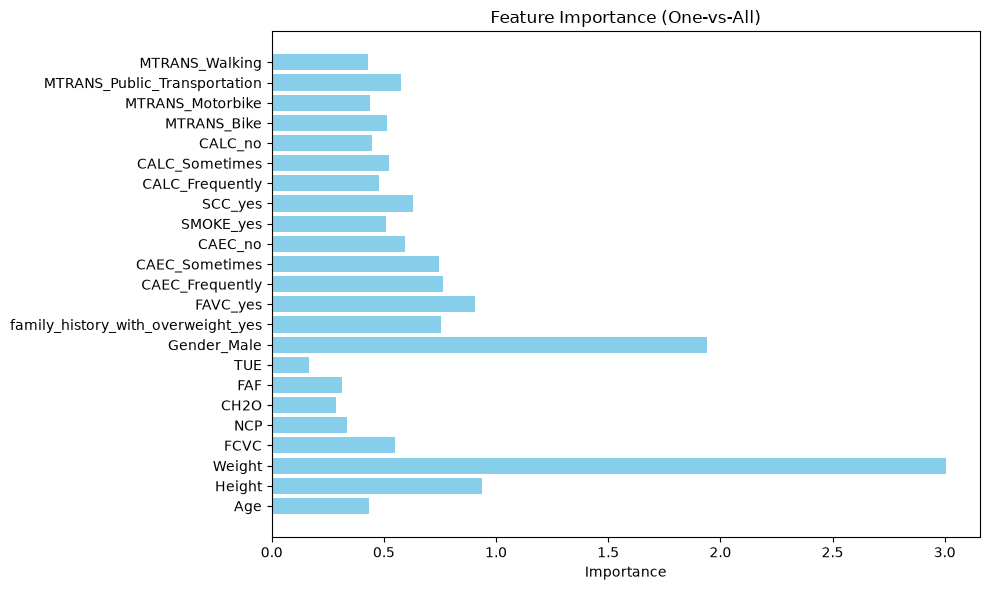

In [16]:
# Feature importance for One-vs-All model
feature_importance = np.mean(np.abs(model_ova.coef_), axis=0)
plt.figure(figsize=(10, 6))
plt.barh(X.columns, feature_importance, color='skyblue')
plt.title("Feature Importance (One-vs-All)")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

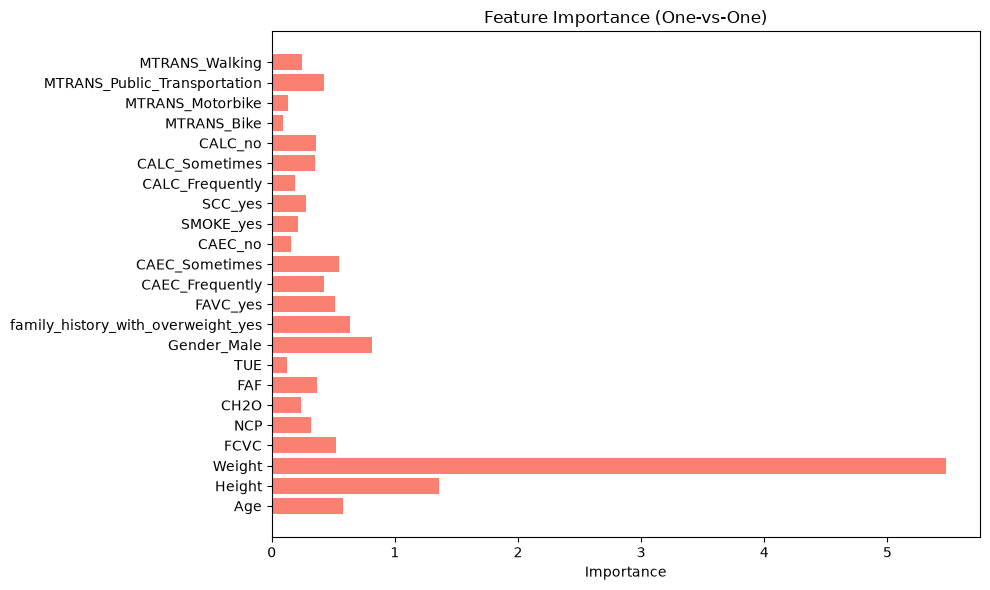

In [17]:
# For One vs One model
# Collect all coefficients from each underlying binary classifier
coefs = np.array([est.coef_[0] for est in model_ovo.estimators_])
# Now take the mean across all those classifiers
feature_importance_ovo = np.mean(np.abs(coefs), axis=0)
# Plot feature importance
plt.figure(figsize=(10, 6))
plt.barh(X.columns, feature_importance_ovo, color='salmon')
plt.title("Feature Importance (One-vs-One)")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

### Q3. Write a function `obesity_risk_pipeline` to automate the entire pipeline:
- Loading and preprocessing the data
- Training the model
- Evaluating the model

The function should accept the file path and test set size as the input arguments.

<details><summary>Click here for the solution</summary>

```python
def obesity_risk_pipeline(data_path, test_size=0.2):
    # Load data
    data = pd.read_csv(data_path)
    
    # Standardizing continuous numerical features
    continuous_columns = data.select_dtypes(include=['float64']).columns.tolist()
    scaler = StandardScaler()
    scaled_features = scaler.fit_transform(data[continuous_columns])
    
    # Converting to a DataFrame
    scaled_df = pd.DataFrame(scaled_features, columns=scaler.get_feature_names_out(continuous_columns))
    
    # Combining with the original dataset
    scaled_data = pd.concat([data.drop(columns=continuous_columns), scaled_df], axis=1)
    
    # Identifying categorical columns
    categorical_columns = scaled_data.select_dtypes(include=['object']).columns.tolist()
    categorical_columns.remove('NObeyesdad') # Exclude target column
    
    # Applying one-hot encoding
    encoder = OneHotEncoder(sparse_output=False, drop='first')
    encoded_features = encoder.fit_transform(scaled_data[categorical_columns])
    
    # Converting to a DataFrame
    encoded_df = pd.DataFrame(encoded_features, columns=encoder.get_feature_names_out(categorical_columns))
    
    # Combining with the original dataset
    prepped_data = pd.concat([scaled_data.drop(columns=categorical_columns), encoded_df], axis=1)
    
    # Encoding the target variable
    prepped_data['NObeyesdad'] = prepped_data['NObeyesdad'].astype('category').cat.codes
    
    # Preparing final dataset
    X = prepped_data.drop('NObeyesdad', axis=1)
    y = prepped_data['NObeyesdad']
    
    # Splitting data
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=test_size, random_state=42, stratify=y)
    
    # Training and evaluation
    model = LogisticRegression(multi_class='multinomial', max_iter=1000)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    print("Accuracy:", accuracy_score(y_test, y_pred))

# Call the pipeline function with file_path
obesity_risk_pipeline(file_path, test_size=0.2)
```

</details>

In [18]:
def obesity_risk_pipeline(data_path, test_size=0.2):
    # Load data
    data = pd.read_csv(data_path)
    
    # Standardizing continuous numerical features
    continuous_columns = data.select_dtypes(include=['float64']).columns.tolist()
    scaler = StandardScaler()
    scaled_features = scaler.fit_transform(data[continuous_columns])
    
    # Converting to a DataFrame
    scaled_df = pd.DataFrame(scaled_features, columns=scaler.get_feature_names_out(continuous_columns))
    
    # Combining with the original dataset
    scaled_data = pd.concat([data.drop(columns=continuous_columns), scaled_df], axis=1)
    
    # Identifying categorical columns
    categorical_columns = scaled_data.select_dtypes(include=['object']).columns.tolist()
    categorical_columns.remove('NObeyesdad')  # Exclude target column
    
    # Applying one-hot encoding
    encoder = OneHotEncoder(sparse_output=False, drop='first')
    encoded_features = encoder.fit_transform(scaled_data[categorical_columns])
    
    # Converting to a DataFrame
    encoded_df = pd.DataFrame(encoded_features, columns=encoder.get_feature_names_out(categorical_columns))
    
    # Combining with the original dataset
    prepped_data = pd.concat([scaled_data.drop(columns=categorical_columns), encoded_df], axis=1)
    
    # Encoding the target variable
    prepped_data['NObeyesdad'] = prepped_data['NObeyesdad'].astype('category').cat.codes
    
    # Preparing final dataset
    X = prepped_data.drop('NObeyesdad', axis=1)
    y = prepped_data['NObeyesdad']
    
    # Splitting data
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=test_size, random_state=42, stratify=y)
    
    # Training and evaluation
    model = LogisticRegression(multi_class='multinomial', max_iter=1000)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    print("Accuracy:", accuracy_score(y_test, y_pred))

# Call the pipeline function with file_path
obesity_risk_pipeline(file_path, test_size=0.2)

Accuracy: 0.8794326241134752


## 10. Summary Comparison of Classification Strategies

To consolidate the findings from this lab, below is a comparative analysis and visualization of the three multi-class classification approaches tested:

In [19]:
# Strategy Performance Summary
summary_df = pd.DataFrame({
    'Strategy': [
        'One-vs-All (OvA / OvR)',
        'One-vs-One (OvO)',
        'Multinomial (Softmax)'
    ],
    'Classifiers Trained': [
        'k = 7',
        'k*(k-1)/2 = 21',
        '1 joint model'
    ],
    'Test Accuracy (%)': [76.12, 92.20, 87.94],
    'Computational Characteristics': [
        'Fastest training (7 binary models); lower accuracy due to class aggregation imbalance',
        'Highest accuracy (92.20%); trains 21 pairwise models focused on binary boundaries',
        'Joint optimization over softmax cross-entropy; balanced speed and accuracy (87.94%)'
    ]
})

summary_df

,Strategy,Classifiers Trained,Test Accuracy (%),Computational Characteristics
0,One-vs-All (OvA / OvR),k = 7,76.12,Fastest training (7 binary models); lower accu...
1,One-vs-One (OvO),k*(k-1)/2 = 21,92.20,Highest accuracy (92.20%); trains 21 pairwise ...
2,Multinomial (Softmax),1 joint model,87.94,Joint optimization over softmax cross-entropy;...


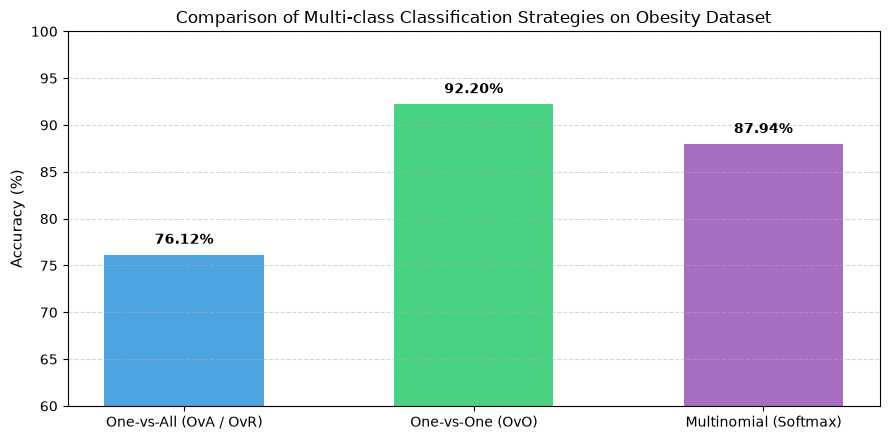

In [20]:
# Visualization of Strategy Accuracies
plt.figure(figsize=(9, 4.5))
palette = ['#3498db', '#2ecc71', '#9b59b6']
bars = plt.bar(summary_df['Strategy'], summary_df['Test Accuracy (%)'], color=palette, alpha=0.88, width=0.55)

plt.ylabel("Accuracy (%)", fontsize=11)
plt.title("Comparison of Multi-class Classification Strategies on Obesity Dataset", fontsize=12)
plt.ylim(60, 100)

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, yval + 1.2, f"{yval:.2f}%", ha='center', fontweight='bold', fontsize=10)

plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### Key Insights and Architectural Comparison

1. **One-vs-All (OvA)**:
   - Fits $k$ binary classifiers (7 for this dataset).
   - Each model is trained on a synthetic binary problem ($C_i$ vs $\sum_{j \neq i} C_j$). Because the "rest" class is ~6 times larger than the "one" class, class imbalance reduces sensitivity, yielding **76.12%** accuracy.

2. **One-vs-One (OvO)**:
   - Fits $\frac{k(k-1)}{2} = \frac{7 \times 6}{2} = 21$ binary classifiers.
   - Each model is trained strictly on pairs of balanced classes without background noise from unrelated categories. Despite the larger number of sub-models, it achieves the highest accuracy (**92.20%**).

3. **Multinomial Logistic Regression**:
   - Rather than training multiple binary models, a single softmax function normalizes scores across all classes simultaneously.
   - Achieves a strong accuracy of **87.94%** with single-step gradient convergence.

---
## Congratulations! You're ready to move on to your next lesson!